In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
# set a sensible renderer for notebook environments; change if you prefer a different renderer
pio.renderers.default = 'notebook'
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("/mnt/G_Pharma/Users/tfang/Cell_Screen/Priscilla_A13_Screen/all_abe_samples_reads_editedrates.csv")

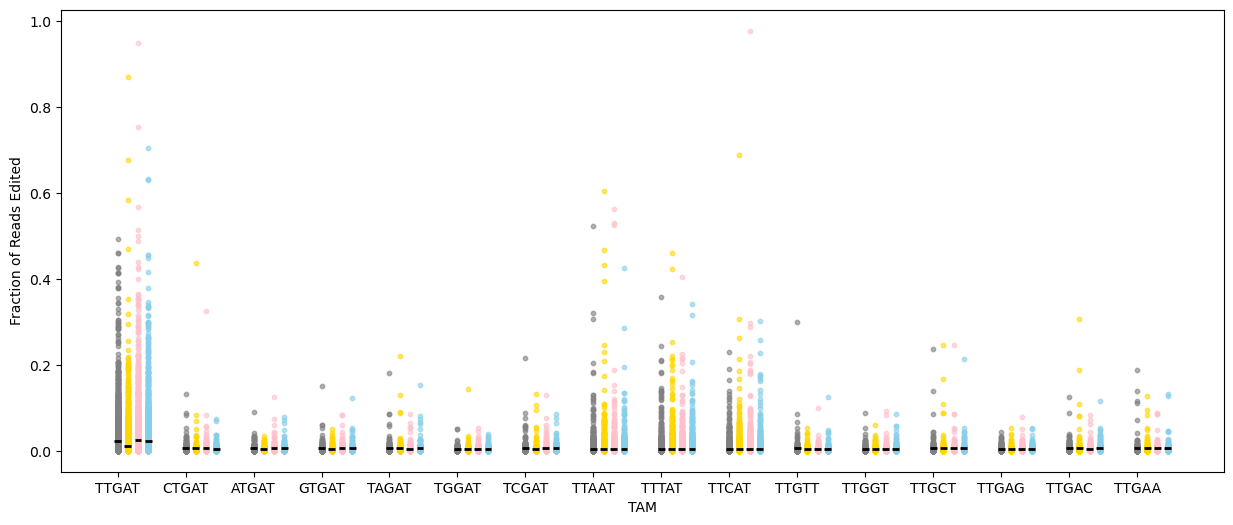

In [3]:
fig, ax = plt.subplots(figsize=(15, 6))
editors = data['editor'].unique()
offset_map = {editor: i * 0.15 for i, editor in enumerate(editors)}

# Define color map
color_map = {editor: 'grey' if editor == 'TnpB-WT_ABE_d10' else 'gold' if editor == 'TnpB-Var1-140_ABE_d10' else 'pink' if editor == 'TnpB-Var2-163_ABE_d10' else 'skyblue' if editor == 'TnpB-Var3-164_ABE_d10' else None for editor in editors}

# Define custom TAM order
tam_order = ['TTGAT', 'CTGAT', 'ATGAT', 'GTGAT', 'TAGAT', 'TGGAT', 'TCGAT', 'TTAAT', 'TTTAT', 'TTCAT', 'TTGTT', 'TTGGT', 'TTGCT', 'TTGAG', 'TTGAC', 'TTGAA']
data['TAM_category'] = pd.Categorical(data['TAM'], categories=tam_order, ordered=True)
data_with_codes = data.copy()
data_with_codes['TAM_numeric'] = data_with_codes['TAM_category'].cat.codes

for editor in editors:
    editor_data = data_with_codes[data_with_codes['editor'] == editor]
    x_offset = editor_data['TAM_numeric'] + offset_map[editor]
    ax.scatter(x_offset, editor_data['frac_reads_edited'], label=editor, alpha=0.6, s=10, color=color_map[editor])
    
    # Calculate mean and plot horizontal lines
    mean_data = editor_data.groupby('TAM_numeric')['frac_reads_edited'].mean()
    x_positions = mean_data.index + offset_map[editor]
    ax.hlines(mean_data.values, x_positions - 0.05, x_positions + 0.05, color='black', linewidth=2)

ax.set_xlabel('TAM')
ax.set_ylabel('Fraction of Reads Edited')
ax.set_xticks(range(len(tam_order)))
ax.set_xticklabels(tam_order)
plt.show()
